<a href="https://colab.research.google.com/github/michelle-rahman/neural-bandit-plus/blob/main/01_data_and_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michelle Rahman

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
RESULTS = '/content/drive/MyDrive/nb_project/results'
os.makedirs(RESULTS, exist_ok=True)

Mounted at /content/drive


In [2]:
from sklearn.datasets import fetch_covtype

ds = fetch_covtype(shuffle=False)
X_raw, y = ds.data, ds.target - 1
print(X_raw.shape)         # should be (581012, 54)
print(np.bincount(y))      # examples per class (7 numbers)

(581012, 54)
[211840 283301  35754   2747   9493  17367  20510]


In [3]:
def binarize(X):
    n = len(X)
    out = np.zeros((n, 94), dtype=np.uint8)
    for j in range(10):
        edges = np.quantile(X[:, j], [0.2, 0.4, 0.6, 0.8])   # 4 cut points -> 5 bins
        b = np.searchsorted(edges, X[:, j], side='right')    # which bin: 0..4
        out[np.arange(n), 5*j + b] = 1                       # one-hot
    out[:, 50:] = X[:, 10:] > 0
    return out

X = binarize(X_raw)

# Shuffle once, as the paper does
perm = np.random.default_rng(0).permutation(len(y))
X, y = X[perm], y[perm]

print(X.shape)                          # (581012, 94)
print(X[:, :50].sum(axis=1)[:5])        # should print [10 10 10 10 10]

(581012, 94)
[10 10 10 10 10]


In [4]:
K, d = 7, 94   # 7 actions, 94 features

def reward(action, label):
    return 1.0 if action == label else 0.0

def run(algo, T, seed=0):
    start = np.random.default_rng(10_000 + seed).integers(len(y))  # random start point
    rewards = np.empty(T, dtype=np.float32)
    for t in range(T):
        i = (start + t) % len(y)          # loop over the dataset
        x = X[i].astype(np.float64)
        a = algo.act(x)                   # algorithm picks an action
        r = reward(a, int(y[i]))          # we reveal ONLY this reward
        algo.update(x, a, r)              # algorithm learns from it
        rewards[t] = r
    return rewards

def cum_regret(rewards):
    return np.cumsum(0.93 - np.asarray(rewards, dtype=float))   # paper's 93% offline reference

In [5]:
class Random:
    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)
    def act(self, x):
        return int(self.rng.integers(K))
    def update(self, x, a, r):
        pass                              # learns nothing

class AlwaysMajority:
    def act(self, x):
        return 1                          # class index 1 is the most common
    def update(self, x, a, r):
        pass

Random accuracy:   0.1429
Majority accuracy: 0.48862


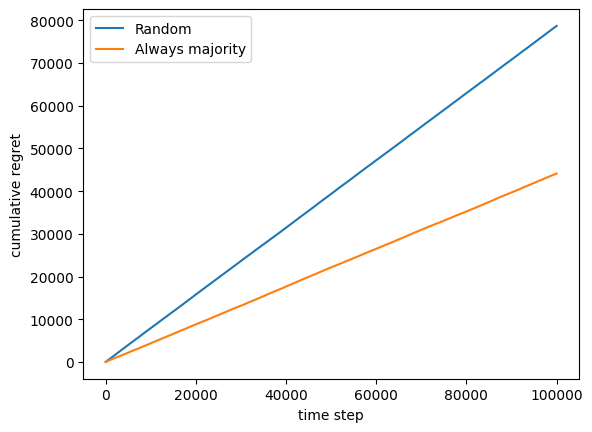

In [6]:
import matplotlib.pyplot as plt

T = 100_000
r_rand = run(Random(), T)
r_maj = run(AlwaysMajority(), T)
print("Random accuracy:  ", r_rand.mean())    # expect about 0.143
print("Majority accuracy:", r_maj.mean())     # expect about 0.488

plt.plot(cum_regret(r_rand), label='Random')
plt.plot(cum_regret(r_maj), label='Always majority')
plt.xlabel('time step'); plt.ylabel('cumulative regret'); plt.legend(); plt.show()

In [7]:
def sample(p, rng):
    return int(min(np.searchsorted(np.cumsum(p), rng.random(), side='right'), len(p) - 1))

class Banditron:
    def __init__(self, gamma=0.005, seed=0):
        self.g = gamma
        self.W = np.zeros((K, d))
        self.rng = np.random.default_rng(seed)
    def act(self, x):
        self.yhat = int(np.argmax(self.W @ x))          # greedy prediction
        self.P = np.full(K, self.g / K)
        self.P[self.yhat] += 1 - self.g                 # P(action)
        return sample(self.P, self.rng)
    def update(self, x, a, r):
        self.W[self.yhat] -= x                          # push away from the guess
        if r > 0:                                       # only if the played action was right
            self.W[a] += x / self.P[a]                  # importance-weighted push toward it

Banditron accuracy: 0.45771
Banditron, last 10k: 0.4758


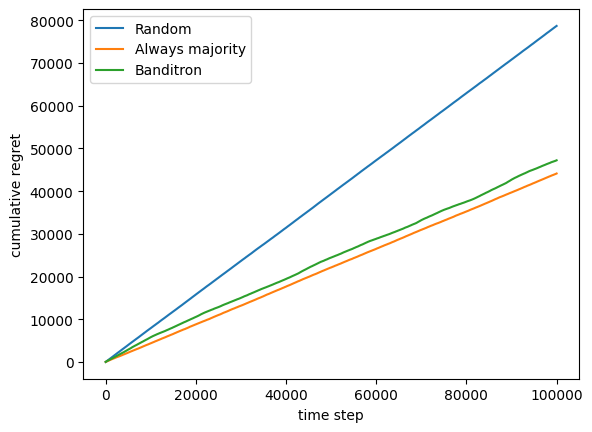

In [8]:
r_ban = run(Banditron(), T)
print("Banditron accuracy:", r_ban.mean())
print("Banditron, last 10k:", r_ban[-10_000:].mean())

plt.plot(cum_regret(r_rand), label='Random')
plt.plot(cum_regret(r_maj), label='Always majority')
plt.plot(cum_regret(r_ban), label='Banditron')
plt.xlabel('time step'); plt.ylabel('cumulative regret'); plt.legend(); plt.show()

In [9]:
r_ban_long = run(Banditron(), 1_000_000)
print("Banditron, last 100k:", r_ban_long[-100_000:].mean())   # paper: about 0.57

Banditron, last 100k: 0.57972
